# Notebook 04: Training Pipeline (with VGG Perceptual Loss & AMP)

Welcome to the **V2 Training Pipeline**!

### What Makes V2 Superior to Standard L1 Training:
1. **Perceptual Loss (VGG-16 Feature Matching):**
   - Instead of just comparing pixel colors, it checks whether high-level textures (foliage, sky gradients, water reflections) match human visual perception.
   - $\text{Loss} = \mathcal{L}_{1} + 0.10 \times \mathcal{L}_{\text{VGG}}$
2. **Cosine Annealing Learning Rate Scheduler:**
   - Smoothly decays the learning rate so the network settles into the optimal color minima in late epochs.
3. **Mixed Precision (`torch.amp`):**
   - Utilizes RTX 4050 Tensor Cores for ~20 seconds per epoch (**25 epochs in ~8–10 minutes**).
4. **Saves to `checkpoints/best_colorizer_v2.pth`** so your existing V1 checkpoint is preserved!

### 1. Import Libraries & Set Device

In [7]:
import os
import sys
# Add project root to sys.path so we can import from src
sys.path.append(os.path.abspath(".."))

import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm

# Custom imports
from src.dataset import make_dataloaders, lab_to_rgb
from src.model import ResNetColorizationNet
from src.loss import ColorizationLoss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Training on: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


### 2. Load Datasets & DataLoaders

In [8]:
train_dir = os.path.join("..", "data", "raw", "train")
val_dir = os.path.join("..", "data", "raw", "val")

train_paths = [os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.endswith((".jpg", ".png"))]
val_paths = [os.path.join(val_dir, f) for f in os.listdir(val_dir) if f.endswith((".jpg", ".png"))]

BATCH_SIZE = 16
train_loader, val_loader = make_dataloaders(train_paths, val_paths, batch_size=BATCH_SIZE, num_workers=0)

print(f"Loaded {len(train_paths)} train images ({len(train_loader)} batches)")
print(f"Loaded {len(val_paths)} val images ({len(val_loader)} batches)")

Loaded 2000 train images (125 batches)
Loaded 200 val images (13 batches)


### 3. Initialize Model, Perceptual Loss & Scheduler
- Set `USE_PERCEPTUAL_LOSS = True` to enable VGG feature matching for vibrant colors.

In [9]:
USE_PERCEPTUAL_LOSS = True
VGG_WEIGHT = 0.10 if USE_PERCEPTUAL_LOSS else 0.0

# 1. Initialize Model
model = ResNetColorizationNet(pretrained=True).to(device)

# 2. Combined L1 + VGG Perceptual Loss
criterion = ColorizationLoss(vgg_weight=VGG_WEIGHT).to(device)

# 3. Optimizer & Cosine Annealing Learning Rate Scheduler
LEARNING_RATE = 2e-4
NUM_EPOCHS = 25
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-5)

# 4. PyTorch AMP Scaler for Mixed Precision
scaler = torch.amp.GradScaler("cuda")

# 5. Checkpoints Directory
checkpoint_dir = os.path.join("..", "checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_filename = "best_colorizer_v2.pth" if USE_PERCEPTUAL_LOSS else "best_colorizer.pth"
best_model_path = os.path.join(checkpoint_dir, checkpoint_filename)

print(f"Loss configuration : L1 + {VGG_WEIGHT} * VGG Perceptual Loss")
print(f"Target checkpoint  : {best_model_path}")

Loss configuration : L1 + 0.1 * VGG Perceptual Loss
Target checkpoint  : ..\checkpoints\best_colorizer_v2.pth


### 4. Helper to Visualize Live Validation Samples

In [10]:
# Pick 3 fixed validation samples to track color progress over epochs
fixed_val_batch = next(iter(val_loader))
fixed_L = fixed_val_batch["L"][:3].to(device)
fixed_ab = fixed_val_batch["ab"][:3]

def show_progress(epoch, current_model):
    current_model.eval()
    with torch.no_grad():
        with torch.amp.autocast("cuda"):
            pred_ab = current_model(fixed_L)
    
    fig, axes = plt.subplots(3, 3, figsize=(10, 9))
    for i in range(3):
        l_cpu = fixed_L[i].cpu()
        target_rgb = lab_to_rgb(l_cpu, fixed_ab[i])
        colorized_rgb = lab_to_rgb(l_cpu, pred_ab[i].float().cpu())
        
        # Column 1: Input Grayscale
        axes[i, 0].imshow(l_cpu.squeeze(), cmap="gray")
        axes[i, 0].set_title("Grayscale Input")
        axes[i, 0].axis("off")
        
        # Column 2: Model Colorization
        axes[i, 1].imshow(colorized_rgb)
        axes[i, 1].set_title(f"Model Output (Epoch {epoch})")
        axes[i, 1].axis("off")
        
        # Column 3: Original Ground Truth
        axes[i, 2].imshow(target_rgb)
        axes[i, 2].set_title("Original Target")
        axes[i, 2].axis("off")
        
    plt.suptitle(f"Live Training Progress at Epoch {epoch} (V2 Perceptual)", fontsize=14)
    plt.tight_layout()
    plt.show()

### 5. Training Loop with Live Tracking

Starting V2 Perceptual Training for 25 epochs...


Epoch 01/25 [Train]: 100%|██████████| 125/125 [01:07<00:00,  1.85it/s, loss=0.1202, l1=0.0663, vgg=0.5389]


Epoch 01/25 | Train: 0.1363 | Val: 0.1217 | LR: 0.000199
  --> Saved new best V2 checkpoint to ..\checkpoints\best_colorizer_v2.pth (Val Loss: 0.1217)


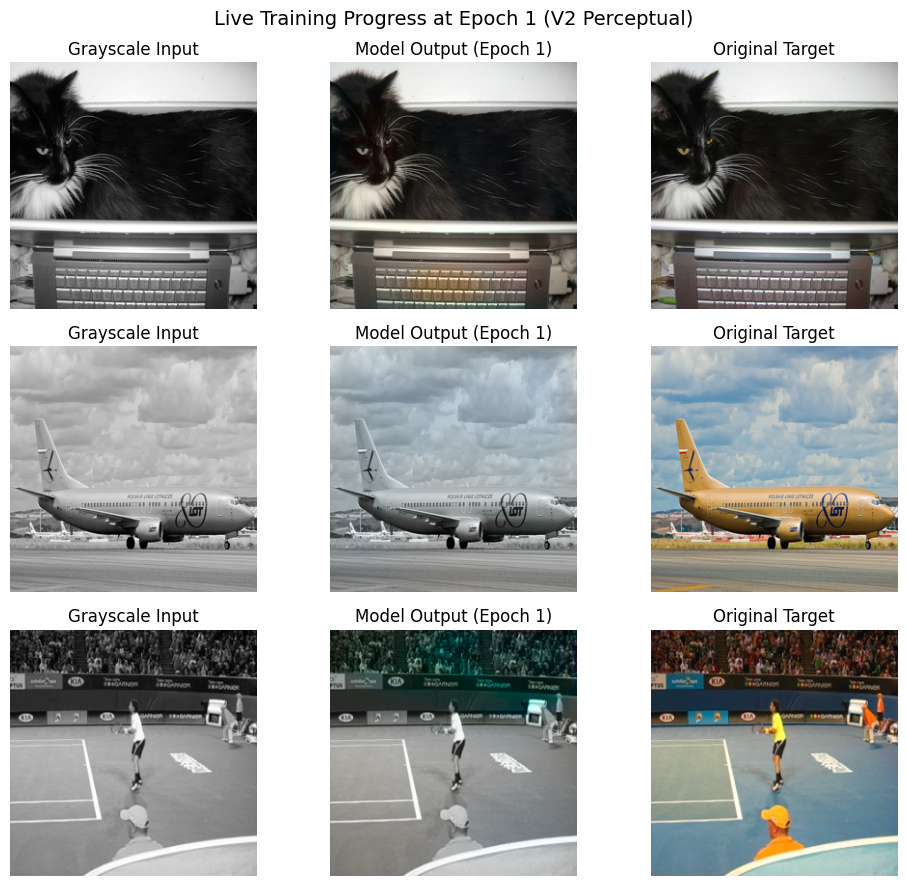

Epoch 02/25 [Train]: 100%|██████████| 125/125 [01:24<00:00,  1.49it/s, loss=0.1231, l1=0.0720, vgg=0.5110]


Epoch 02/25 | Train: 0.1210 | Val: 0.1229 | LR: 0.000197


Epoch 03/25 [Train]: 100%|██████████| 125/125 [01:00<00:00,  2.06it/s, loss=0.1336, l1=0.0854, vgg=0.4819]


Epoch 03/25 | Train: 0.1187 | Val: 0.1228 | LR: 0.000193


Epoch 04/25 [Train]: 100%|██████████| 125/125 [01:22<00:00,  1.52it/s, loss=0.1281, l1=0.0810, vgg=0.4706]


Epoch 04/25 | Train: 0.1165 | Val: 0.1325 | LR: 0.000188


Epoch 05/25 [Train]: 100%|██████████| 125/125 [01:25<00:00,  1.47it/s, loss=0.0972, l1=0.0533, vgg=0.4387]


Epoch 05/25 | Train: 0.1148 | Val: 0.1257 | LR: 0.000182


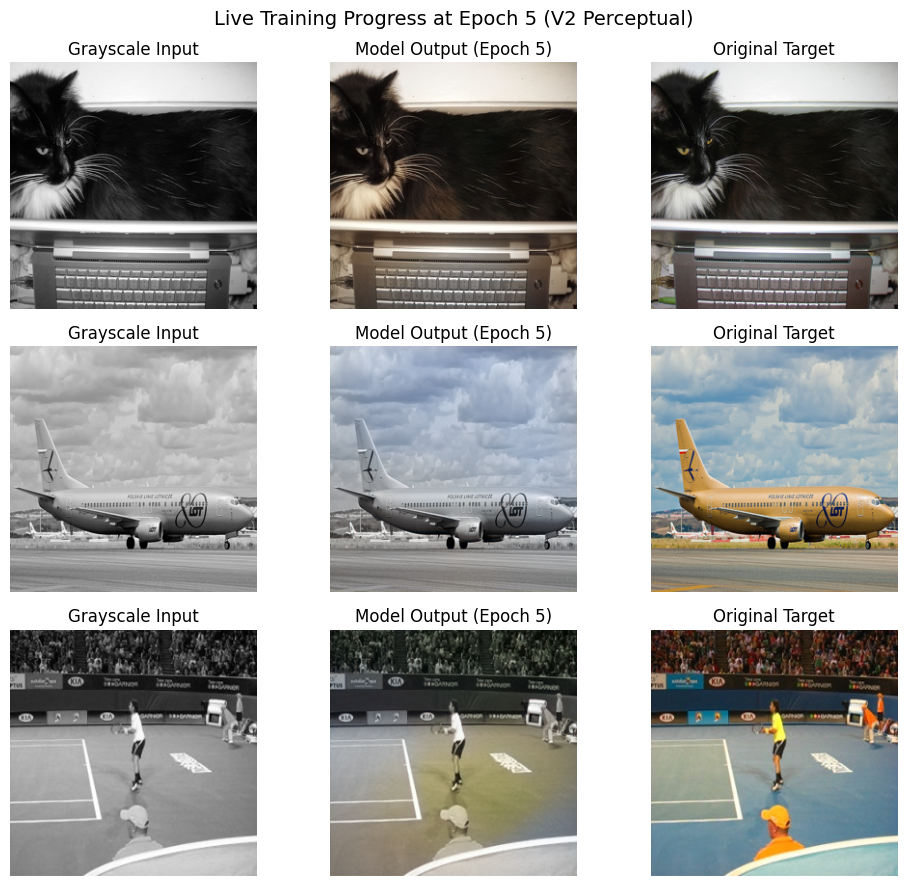

Epoch 06/25 [Train]: 100%|██████████| 125/125 [01:27<00:00,  1.43it/s, loss=0.1315, l1=0.0776, vgg=0.5391]


Epoch 06/25 | Train: 0.1123 | Val: 0.1158 | LR: 0.000174
  --> Saved new best V2 checkpoint to ..\checkpoints\best_colorizer_v2.pth (Val Loss: 0.1158)


Epoch 07/25 [Train]: 100%|██████████| 125/125 [01:26<00:00,  1.45it/s, loss=0.1115, l1=0.0600, vgg=0.5154]


Epoch 07/25 | Train: 0.1097 | Val: 0.1194 | LR: 0.000166


Epoch 08/25 [Train]: 100%|██████████| 125/125 [01:32<00:00,  1.34it/s, loss=0.0956, l1=0.0526, vgg=0.4300]


Epoch 08/25 | Train: 0.1085 | Val: 0.1175 | LR: 0.000156


Epoch 09/25 [Train]: 100%|██████████| 125/125 [01:25<00:00,  1.46it/s, loss=0.1029, l1=0.0541, vgg=0.4887]


Epoch 09/25 | Train: 0.1072 | Val: 0.1180 | LR: 0.000145


Epoch 10/25 [Train]: 100%|██████████| 125/125 [01:27<00:00,  1.42it/s, loss=0.1149, l1=0.0631, vgg=0.5180]


Epoch 10/25 | Train: 0.1047 | Val: 0.1214 | LR: 0.000134


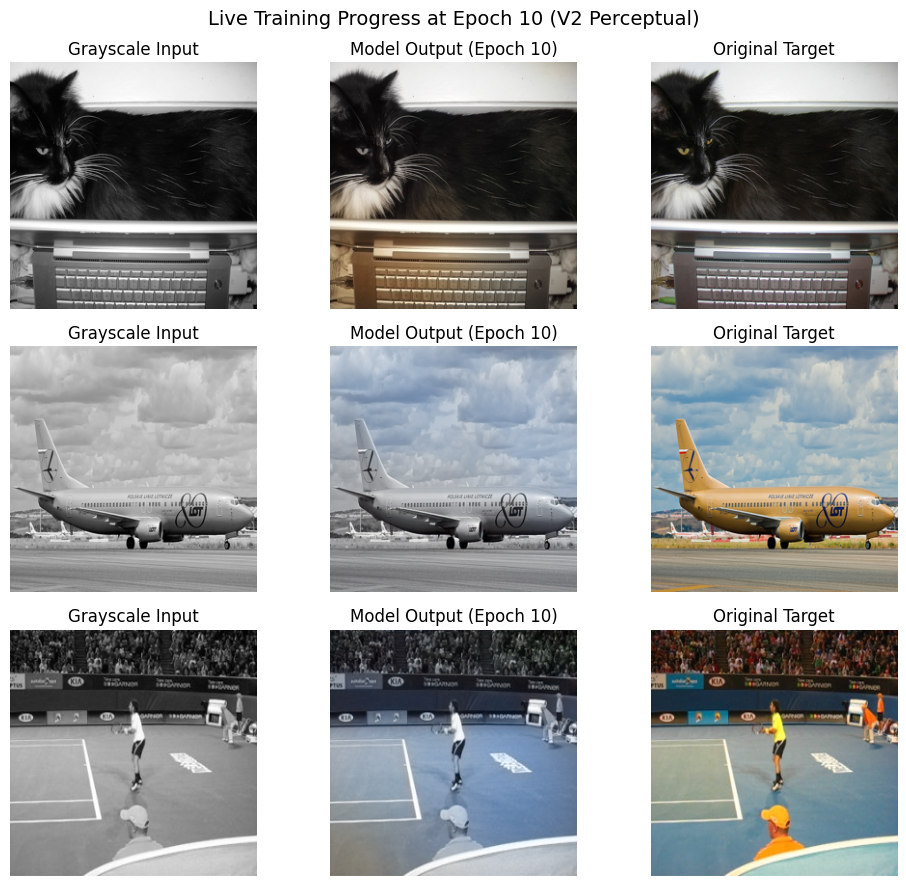

Epoch 11/25 [Train]: 100%|██████████| 125/125 [01:29<00:00,  1.40it/s, loss=0.0878, l1=0.0446, vgg=0.4324]


Epoch 11/25 | Train: 0.1031 | Val: 0.1164 | LR: 0.000123


Epoch 12/25 [Train]: 100%|██████████| 125/125 [01:15<00:00,  1.66it/s, loss=0.0877, l1=0.0474, vgg=0.4030]


Epoch 12/25 | Train: 0.1015 | Val: 0.1164 | LR: 0.000111


Epoch 13/25 [Train]: 100%|██████████| 125/125 [01:31<00:00,  1.36it/s, loss=0.1121, l1=0.0540, vgg=0.5805]


Epoch 13/25 | Train: 0.0996 | Val: 0.1152 | LR: 0.000099
  --> Saved new best V2 checkpoint to ..\checkpoints\best_colorizer_v2.pth (Val Loss: 0.1152)


Epoch 14/25 [Train]: 100%|██████████| 125/125 [01:12<00:00,  1.73it/s, loss=0.0887, l1=0.0440, vgg=0.4469]


Epoch 14/25 | Train: 0.0996 | Val: 0.1188 | LR: 0.000087


Epoch 15/25 [Train]: 100%|██████████| 125/125 [01:15<00:00,  1.65it/s, loss=0.0908, l1=0.0509, vgg=0.3989]


Epoch 15/25 | Train: 0.0977 | Val: 0.1157 | LR: 0.000076


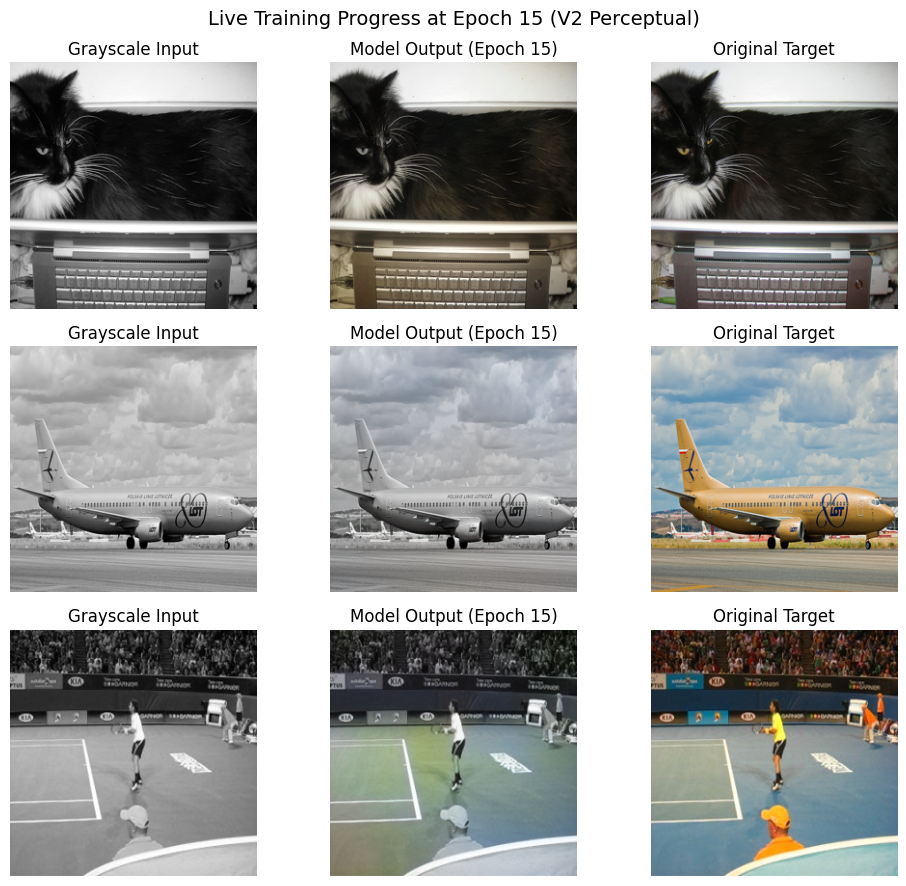

Epoch 16/25 [Train]: 100%|██████████| 125/125 [01:29<00:00,  1.39it/s, loss=0.0877, l1=0.0476, vgg=0.4018]


Epoch 16/25 | Train: 0.0960 | Val: 0.1153 | LR: 0.000065


Epoch 17/25 [Train]: 100%|██████████| 125/125 [01:27<00:00,  1.44it/s, loss=0.1033, l1=0.0498, vgg=0.5351]


Epoch 17/25 | Train: 0.0944 | Val: 0.1163 | LR: 0.000054


Epoch 18/25 [Train]: 100%|██████████| 125/125 [01:22<00:00,  1.52it/s, loss=0.0854, l1=0.0440, vgg=0.4133]


Epoch 18/25 | Train: 0.0930 | Val: 0.1153 | LR: 0.000044


Epoch 19/25 [Train]: 100%|██████████| 125/125 [01:37<00:00,  1.28it/s, loss=0.1020, l1=0.0552, vgg=0.4681]


Epoch 19/25 | Train: 0.0921 | Val: 0.1147 | LR: 0.000036
  --> Saved new best V2 checkpoint to ..\checkpoints\best_colorizer_v2.pth (Val Loss: 0.1147)


Epoch 20/25 [Train]: 100%|██████████| 125/125 [01:19<00:00,  1.57it/s, loss=0.0983, l1=0.0493, vgg=0.4903]


Epoch 20/25 | Train: 0.0908 | Val: 0.1151 | LR: 0.000028


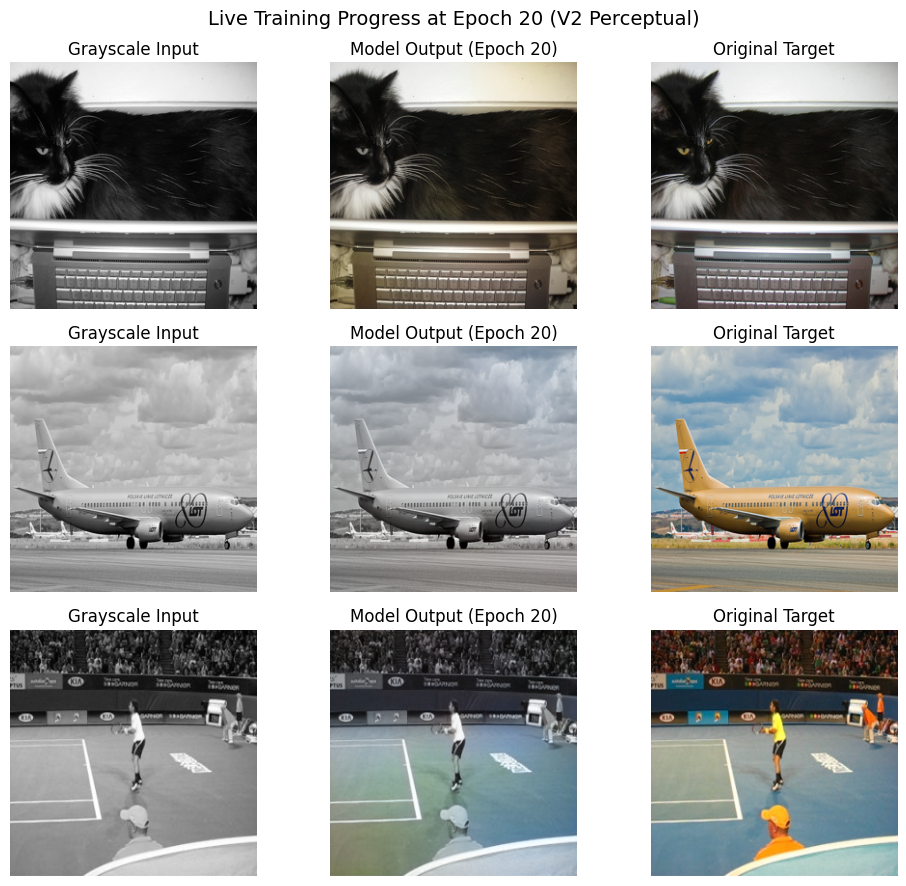

Epoch 21/25 [Train]: 100%|██████████| 125/125 [01:42<00:00,  1.22it/s, loss=0.0969, l1=0.0565, vgg=0.4047]


Epoch 21/25 | Train: 0.0900 | Val: 0.1159 | LR: 0.000022


Epoch 22/25 [Train]: 100%|██████████| 125/125 [01:11<00:00,  1.75it/s, loss=0.0838, l1=0.0391, vgg=0.4469]


Epoch 22/25 | Train: 0.0890 | Val: 0.1152 | LR: 0.000017


Epoch 23/25 [Train]: 100%|██████████| 125/125 [01:20<00:00,  1.54it/s, loss=0.0838, l1=0.0397, vgg=0.4409]


Epoch 23/25 | Train: 0.0884 | Val: 0.1155 | LR: 0.000013


Epoch 24/25 [Train]: 100%|██████████| 125/125 [01:16<00:00,  1.64it/s, loss=0.0898, l1=0.0419, vgg=0.4787]


Epoch 24/25 | Train: 0.0880 | Val: 0.1156 | LR: 0.000011


Epoch 25/25 [Train]: 100%|██████████| 125/125 [01:23<00:00,  1.49it/s, loss=0.0891, l1=0.0460, vgg=0.4304]


Epoch 25/25 | Train: 0.0876 | Val: 0.1156 | LR: 0.000010


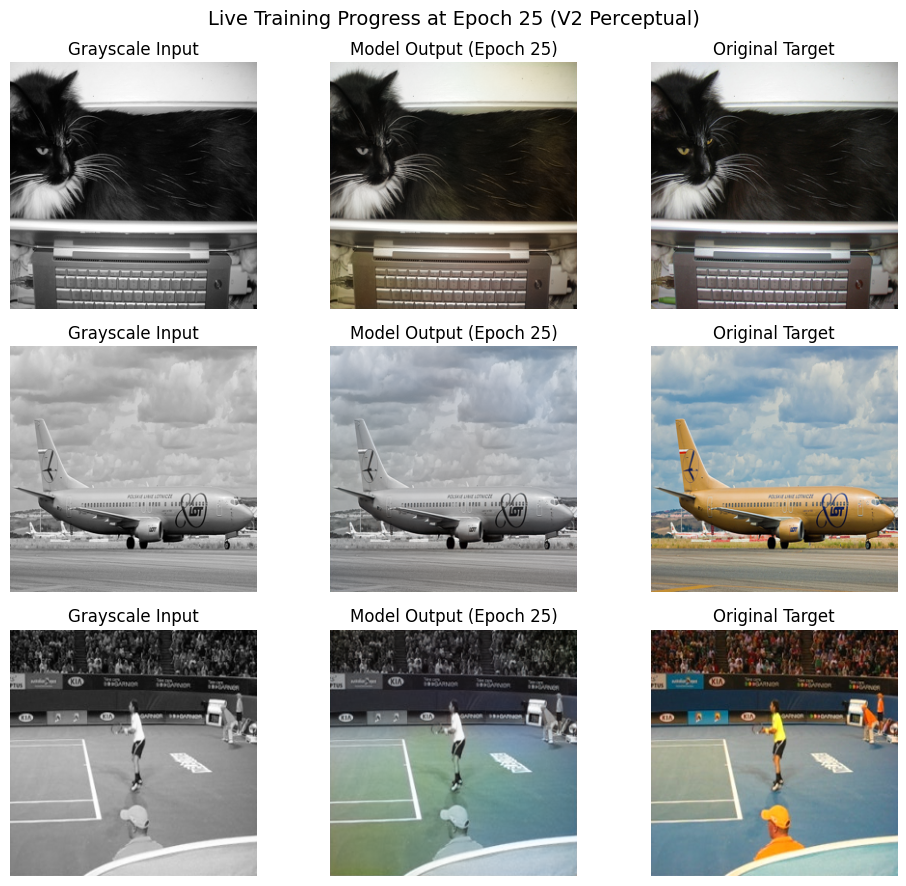


V2 Training complete in 37.5 minutes! Best Val Loss: 0.1147


In [11]:
train_losses, val_losses = [], []
best_val_loss = float("inf")
start_train_time = time.time()

print(f"Starting V2 Perceptual Training for {NUM_EPOCHS} epochs...")

for epoch in range(1, NUM_EPOCHS + 1):
    # --- 1. Training Phase ---
    model.train()
    running_train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [Train]")
    for batch in pbar:
        L = batch["L"].to(device, non_blocking=True)
        ab = batch["ab"].to(device, non_blocking=True)
        
        optimizer.zero_grad()
        
        # Forward pass with Automatic Mixed Precision
        with torch.amp.autocast("cuda"):
            pred_ab = model(L)
            total_loss, l1_part, vgg_part = criterion(L, pred_ab, ab)
            
        # Backward pass with scaled gradients
        scaler.scale(total_loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_train_loss += total_loss.item() * L.size(0)
        pbar.set_postfix({"loss": f"{total_loss.item():.4f}", "l1": f"{l1_part.item():.4f}", "vgg": f"{vgg_part.item():.4f}"})
        
    scheduler.step()
    epoch_train_loss = running_train_loss / len(train_paths)
    train_losses.append(epoch_train_loss)
    
    # --- 2. Validation Phase ---
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            L = batch["L"].to(device, non_blocking=True)
            ab = batch["ab"].to(device, non_blocking=True)
            with torch.amp.autocast("cuda"):
                pred_ab = model(L)
                total_loss, _, _ = criterion(L, pred_ab, ab)
            running_val_loss += total_loss.item() * L.size(0)
            
    epoch_val_loss = running_val_loss / len(val_paths)
    val_losses.append(epoch_val_loss)
    current_lr = scheduler.get_last_lr()[0]
    
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} | Train: {epoch_train_loss:.4f} | Val: {epoch_val_loss:.4f} | LR: {current_lr:.6f}")
    
    # --- 3. Save Best Checkpoint ---
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": best_val_loss,
            "vgg_weight": VGG_WEIGHT
        }, best_model_path)
        print(f"  --> Saved new best V2 checkpoint to {best_model_path} (Val Loss: {best_val_loss:.4f})")
        
    # --- 4. Live Visual Preview every 5 epochs ---
    if epoch % 5 == 0 or epoch == 1:
        show_progress(epoch, model)

total_time = (time.time() - start_train_time) / 60.0
print(f"\nV2 Training complete in {total_time:.1f} minutes! Best Val Loss: {best_val_loss:.4f}")

### 6. Plot Loss Curves

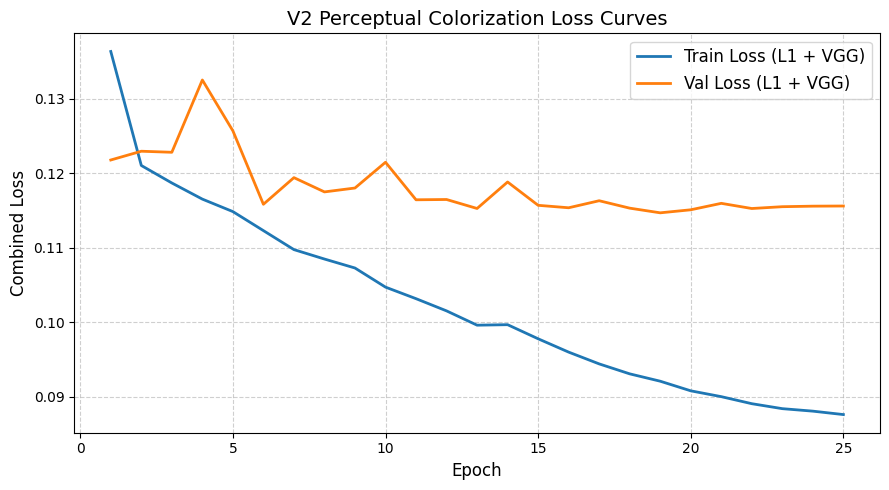

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label="Train Loss (L1 + VGG)", color="#1f77b4", lw=2)
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, label="Val Loss (L1 + VGG)", color="#ff7f0e", lw=2)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Combined Loss", fontsize=12)
plt.title("V2 Perceptual Colorization Loss Curves", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join("..", "outputs", "loss_curves_v2.png"))
plt.show()